# Bayesian CART versus RRT: prior sensitivity

The new experiment fixes BCART's $\beta=2$ and compares leaf-mean prior
SDs $\tau\in\{1,2,5,10\}$ with RRT(1), using the same generated data.
The loader selects the uploaded `bcart_tau_<start>_<end>.pkl` checkpoints.
It does not pool these with the earlier beta experiment. Rerun all cells
after replacing the partial checkpoints with more recent results.

A checkpoint can contain fewer completed replications than its filename's
assigned range; counts below reflect the saved observations.

The four panels show coverage, scaled interval length
($|C_A|\sqrt{n_A}$), test MSE, and inference runtime. Runtime is recorded
in seconds and plotted in minutes. For RRT it excludes tree fitting;
for BCART it includes posterior sampling and interval construction.

In the plots, `BCART(k)` denotes prior standard deviation $\tau=k$; all BCART fits have $\beta=2$.

In [1]:
from pathlib import Path
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [2]:
# Optional overrides: DATA_DIR = Path("..."); RESULT_PREFIX = "bcart_tau"
DATA_DIR = None
RESULT_PREFIX = "bcart_tau"
relative_dir = Path("Simulations/Results/toy_example/bayesianCART")

def checkpoint_paths(directory, prefix):
    pattern = re.compile(rf"{re.escape(prefix)}_(\d+)_(\d+)\.pkl")
    return sorted(
        (path for path in directory.glob(f"{prefix}_*.pkl")
         if pattern.fullmatch(path.name)),
        key=lambda path: tuple(map(int, pattern.fullmatch(path.name).groups())),
    )

# Support kernels started in the notebook folder or anywhere in the repo.
if DATA_DIR is None:
    candidates = [parent / relative_dir for parent in (Path.cwd(), *Path.cwd().parents)]
    candidates.append(Path.cwd())
else:
    candidates = [Path(DATA_DIR)]
prefixes = [RESULT_PREFIX] if RESULT_PREFIX is not None else ["bcart_tau", "bcart"]
discovered = next(
    ((directory, prefix) for prefix in prefixes for directory in candidates
     if checkpoint_paths(directory, prefix)), None)
if discovered is None:
    raise FileNotFoundError("No BCART checkpoints found. Set DATA_DIR and RESULT_PREFIX.")
DATA_DIR, RESULT_PREFIX = discovered
DATA_DIR = DATA_DIR.resolve()
filename_pattern = re.compile(rf"{re.escape(RESULT_PREFIX)}_(\d+)_(\d+)\.pkl")
files_list = checkpoint_paths(DATA_DIR, RESULT_PREFIX)
print(f"Results directory: {DATA_DIR}")
print(f"Selected experiment prefix: {RESULT_PREFIX}")
print(f"Found {len(files_list)} checkpoint files.")

Results directory: /Users/yilingh/Desktop/PhD/SI_Codes/SI-CART/Simulations/Results/toy_example/bayesianCART
Selected experiment prefix: bcart_tau
Found 20 checkpoint files.


In [3]:
metrics = ["Coverage Rate", "Length", "MSE", "Inference Time"]
frames, progress = [], []
for path in files_list:
    start, end = map(int, filename_pattern.fullmatch(path.name).groups())
    saved = joblib.load(path)
    required = {"Method", "SD(Y)", *metrics}
    if not isinstance(saved, dict) or not required.issubset(saved):
        raise ValueError(f"{path.name}: expected the BCART results dictionary including Inference Time")
    if len({len(saved[key]) for key in required}) != 1:
        raise ValueError(f"{path.name}: result columns have different lengths")
    frame = pd.DataFrame({key: saved[key] for key in ["Method", "SD(Y)", *metrics]})
    if frame.empty:
        continue
    # Each method is recorded once per replication, beginning at start.
    frame["Replication"] = start + frame.groupby("Method", sort=False).cumcount()
    if (frame["Replication"] >= end).any():
        raise ValueError(f"{path.name}: saved rows exceed the assigned segment")
    frame["Source File"] = path.name
    frames.append(frame)
    progress.append({"File": path.name, "Start": start, "End": end,
                     "Saved replications": frame["Replication"].nunique(),
                     "Assigned replications": end - start})

if not frames:
    raise ValueError("The checkpoints contain no saved results")
results = pd.concat(frames, ignore_index=True)
if results.duplicated(["Replication", "Method"]).any():
    raise ValueError("Overlapping checkpoints contain duplicate replication/method rows")
for metric in metrics:
    results[metric] = pd.to_numeric(results[metric], errors="raise")
if results["SD(Y)"].nunique() != 1:
    raise ValueError("These plots expect one noise setting; filter SD(Y) before combining experiments")
results["Inference Time (min)"] = results["Inference Time"] / 60
progress_df = pd.DataFrame(progress)
print(f"Loaded {results['Replication'].nunique()} saved replications across "
      f"{len(progress_df)} files ({len(results)} method/replication rows).")
print("Rows per method:")
print(results.groupby("Method", sort=False).size().to_string())
display(progress_df)

Loaded 100 saved replications across 20 files (500 method/replication rows).
Rows per method:
Method
RRT                      100
BCART(beta=2, tau=1)     100
BCART(beta=2, tau=2)     100
BCART(beta=2, tau=5)     100
BCART(beta=2, tau=10)    100


,File,Start,End,Saved replications,Assigned replications
0,bcart_tau_0_5.pkl,0,5,5,5
1,bcart_tau_5_10.pkl,5,10,5,5
2,bcart_tau_10_15.pkl,10,15,5,5
3,bcart_tau_15_20.pkl,15,20,5,5
4,bcart_tau_20_25.pkl,20,25,5,5
5,bcart_tau_25_30.pkl,25,30,5,5
6,bcart_tau_30_35.pkl,30,35,5,5
7,bcart_tau_35_40.pkl,35,40,5,5
8,bcart_tau_40_45.pkl,40,45,5,5
9,bcart_tau_45_50.pkl,45,50,5,5


In [4]:
def method_sort_key(method):
    if method.startswith("RRT"):
        return (0, 0, 0, method)
    match = re.fullmatch(r"BCART\(beta=([^,]+), tau=([^\)]+)\)", method)
    if match:
        return (1, float(match.group(1)), float(match.group(2)), method)
    return (2, 0, 0, method)

method_order = sorted(results["Method"].unique(), key=method_sort_key)
summary = results.groupby("Method").agg(
    Replications=("Replication", "nunique"),
    Coverage=("Coverage Rate", "mean"),
    Scaled_length=("Length", "mean"),
    Test_MSE=("MSE", "mean"),
    Runtime_seconds=("Inference Time", "mean"),
    Runtime_minutes=("Inference Time (min)", "mean"),
).reindex(method_order)
display(summary.round(3))

,Replications,Coverage,Scaled_length,Test_MSE,Runtime_seconds,Runtime_minutes
Method,,,,,,
RRT,100,0.906,6.485,4.719,153.278,2.555
"BCART(beta=2, tau=1)",100,0.858,6.920,4.800,657.800,10.963
"BCART(beta=2, tau=2)",100,0.913,7.123,4.445,659.619,10.994
"BCART(beta=2, tau=5)",100,0.914,7.103,4.394,657.368,10.956
"BCART(beta=2, tau=10)",100,0.910,7.015,4.407,655.192,10.920


The plotting style matches the reference toy-example notebook: green
Seaborn boxplots, no outlier points, turquoise downward triangles for
mean coverage, and dotted grey reference lines for 90% coverage and
RRT's mean MSE. The axes use the same Method labels, with redundant y-axis labels omitted, coverage
range [0, 1], interval-length range [0, 35], and MSE range [3, 6.5].

Runtime is in minutes. Each mean and boxplot uses the saved replication
values; hidden outlier points are still included in the means. Rerun
all cells after adding or replacing worker checkpoints.

Coverage :
 RRT(1)       0.905714
BCART(1)     0.857667
BCART(2)     0.912833
BCART(5)     0.914500
BCART(10)    0.910333
dtype: float64
Length :
 RRT(1)       6.485265
BCART(1)     6.919618
BCART(2)     7.122851
BCART(5)     7.103403
BCART(10)    7.014989
dtype: float64
MSE :
 RRT(1)       4.719022
BCART(1)     4.800253
BCART(2)     4.444516
BCART(5)     4.394195
BCART(10)    4.406840
dtype: float64
Runtime (minutes) :
 RRT(1)        2.554625
BCART(1)     10.963331
BCART(2)     10.993657
BCART(5)     10.956132
BCART(10)    10.919868
dtype: float64


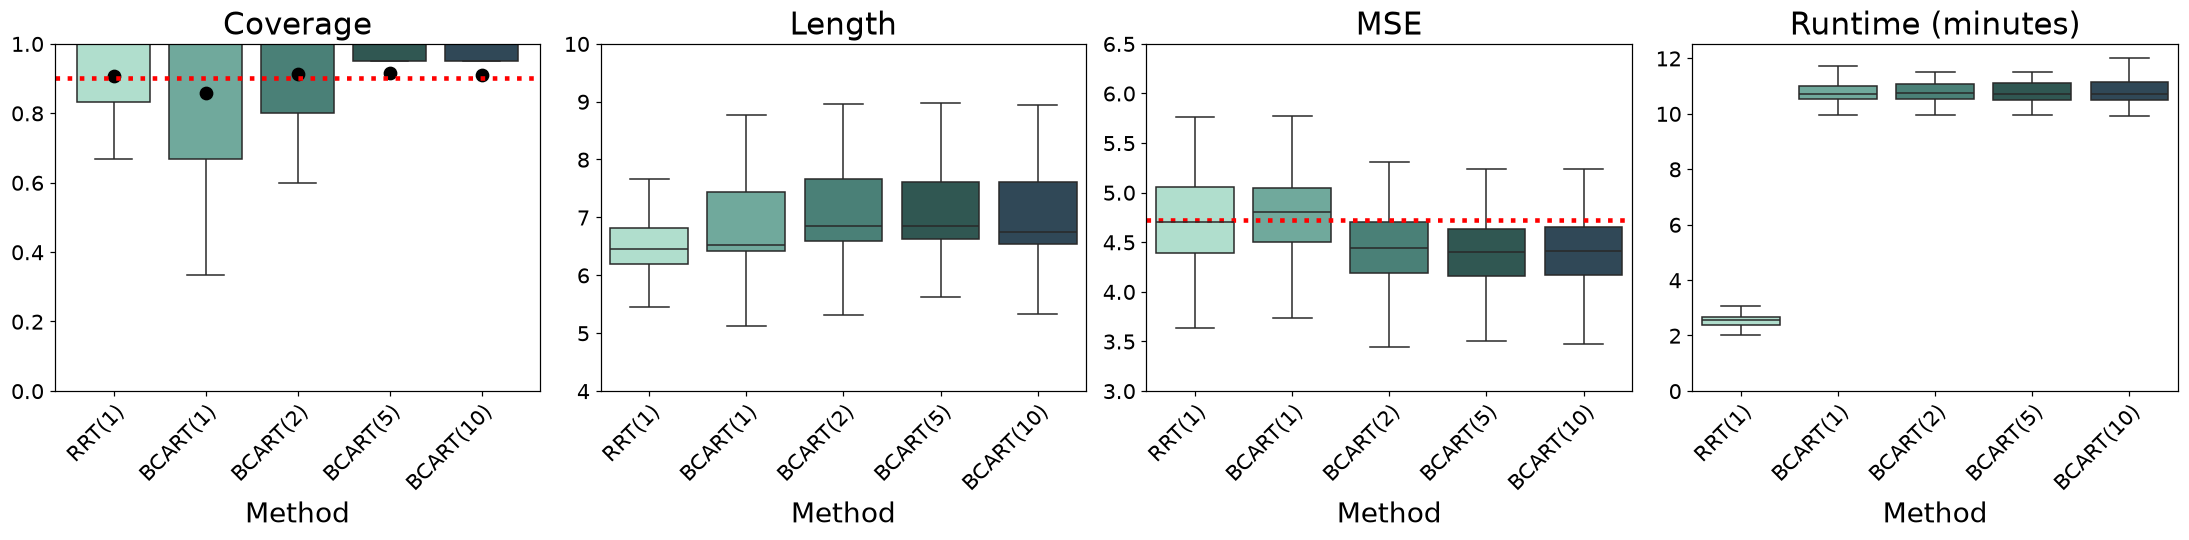

In [37]:
def method_label(method):
    match = re.fullmatch(r"BCART\(beta=([^,]+), tau=([^\)]+)\)", method)
    if match:
        return f"BCART({float(match.group(2)):g})"
    return "RRT(1)" if method == "RRT" else method

col_names = [method_label(method) for method in method_order]
if len(set(col_names)) != len(col_names):
    raise ValueError("BCART(tau) labels require a single beta value; select one beta first")

# Same wide-frame input and formatting as the reference toy notebook.
coverage_df, length_df, MSE_df, runtime_df = [
    results.pivot(index="Replication", columns="Method", values=metric)
           .reindex(columns=method_order)
    for metric in ["Coverage Rate", "Length", "MSE", "Inference Time (min)"]
]

def boxplots(dfs, metrics, len_lim=35, MSE_lim=6.5, runtime_lim=None,
             MSE_baseline_key="RRT(1)", col_names=None, palette=None,
             title_fontsize=20, label_fontsize=18, tick_fontsize=14):
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i, (df, metric) in enumerate(zip(dfs, metrics)):
        df = df.copy()
        if col_names is not None:
            df.columns = col_names
        sns.boxplot(data=df, ax=axes[i], palette=palette,
                    showfliers=False, showmeans=False)
        axes[i].set_title(metric, fontsize=title_fontsize)
        axes[i].set_xlabel("Method", fontsize=label_fontsize)
        axes[i].set_ylabel("")
        axes[i].tick_params(axis="both", labelsize=tick_fontsize)
        plt.setp(axes[i].get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

        means = df.mean()
        print(metric, ":\n", means.T)
        if metric == "Coverage":
            for j, mean in enumerate(means):
                axes[i].plot(j, mean, marker="o", color="#000000", markersize=8)
            axes[i].set_ylim(0, 1)
            axes[i].axhline(y=.9, linestyle="dotted", color="red", linewidth=3)
        elif metric == "Length":
            axes[i].set_ylim(4, len_lim)
        elif metric == "MSE":
            axes[i].set_ylim(3, MSE_lim)
            if MSE_baseline_key:
                axes[i].axhline(y=means[MSE_baseline_key], linestyle="dotted",
                                color="red", linewidth=3)
        elif metric == "Runtime (minutes)":
            axes[i].set_ylim(bottom=0, top=runtime_lim)

    plt.tight_layout()
    plt.show()
    return fig, axes

fig, axes = boxplots(
    dfs=[coverage_df, length_df, MSE_df, runtime_df],
    metrics=["Coverage", "Length", "MSE", "Runtime (minutes)"],
    len_lim=10, MSE_lim=6.5,
    MSE_baseline_key="RRT(1)", col_names=col_names,
    palette=["#A8E6CF", "#66B2A2", "#41897D", "#2A5D57", "#2A4A5D"],
    title_fontsize=20, label_fontsize=18, tick_fontsize=14,
)

In [38]:
output_stem = DATA_DIR / f"{RESULT_PREFIX}_vs_rrt_four_panels"
fig.savefig(output_stem.with_suffix(".png"), dpi=300, bbox_inches="tight")
fig.savefig(output_stem.with_suffix(".pdf"), bbox_inches="tight")
print(f"Saved {output_stem.with_suffix('.png')}")
print(f"Saved {output_stem.with_suffix('.pdf')}")

Saved /Users/yilingh/Desktop/PhD/SI_Codes/SI-CART/Simulations/Results/toy_example/bayesianCART/bcart_tau_vs_rrt_four_panels.png
Saved /Users/yilingh/Desktop/PhD/SI_Codes/SI-CART/Simulations/Results/toy_example/bayesianCART/bcart_tau_vs_rrt_four_panels.pdf
